In [1]:
import numpy as np
import pandas as pd

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

# Chi-Square Goodness-of-Fit Test

## Problem: Is a Six-Sided Die Fair?

Suppose a six-sided die is rolled 60 times. We observe the following frequencies:

| Die Face | Observed Frequency |
|---|---:|
| 1 | 8 |
| 2 | 12 |
| 3 | 9 |
| 4 | 11 |
| 5 | 10 |
| 6 | 10 |
| **Total** | **60** |

Our objective is to determine whether these observed frequencies provide statistically significant evidence that the die does not follow a uniform distribution.

### Hypotheses

- **Null hypothesis (\(H_0\)):** The die is fair, and each face has a probability of \(1/6\).
- **Alternative hypothesis (\(H_1\)):** The probabilities of the six faces are not all equal.

We use the Chi-Square Goodness-of-Fit Test because we have one categorical variable (die face) and want to compare its observed frequencies against a specified probability distribution.

The significance level is \(\alpha=0.05\).

In [5]:

from scipy.stats import chisquare, chi2

observed = np.array([8, 12, 9, 11, 10, 10])
faces = np.arange(1, 7)

n = observed.sum()
k = len(observed)
alpha = 0.05

print("Total rolls:", n)
print("Number of categories:", k)

Total rolls: 60
Number of categories: 6


## 1. Calculate Expected Frequencies

Under the null hypothesis, each face has an equal probability of \(1/6\).

The expected frequency for each face is:

\[
E_i=np_i
\]

Therefore,

\[
E_i=60\times\frac{1}{6}=10
\]

If the die follows a uniform distribution, each face is expected to appear 10 times over 60 rolls. Random sampling variation means the observed frequencies do not need to match the expected frequencies exactly.

We calculate the expected frequencies and compare them with the observed counts.

In [6]:
expected_probabilities = np.full(k, 1 / k)
expected = n * expected_probabilities

frequency_table = pd.DataFrame({
    "Face": faces,
    "Observed": observed,
    "Expected": expected
})

display(frequency_table)

,Face,Observed,Expected
0,1,8,10.0
1,2,12,10.0
2,3,9,10.0
3,4,11,10.0
4,5,10,10.0
5,6,10,10.0


## 2. Check the Assumptions

Before performing the test, we check the following requirements:

1. **Categorical outcomes:** Each roll produces one of the six die faces.
2. **Mutually exclusive categories:** Every roll belongs to exactly one face.
3. **Independent observations:** The outcome of one roll should not determine the outcome of another. This depends on how the rolls are conducted and cannot be verified from frequency counts alone.
4. **Sufficient expected frequencies:** A common practical guideline is that every expected count should be at least 5. Here, each expected count is 10.

The expected-count condition is satisfied. We assume that the die rolls were conducted independently.

In [7]:
print("Observed total:", observed.sum())
print("Expected total:", expected.sum())
print("Minimum expected frequency:", expected.min())

print(
    "All expected frequencies >= 5:",
    np.all(expected >= 5)
)

print(
    "Observed and expected totals match:",
    np.isclose(observed.sum(), expected.sum())
)

Observed total: 60
Expected total: 60.0
Minimum expected frequency: 10.0
All expected frequencies >= 5: True
Observed and expected totals match: True


## 3. Visualize Observed vs Expected Frequencies

A grouped bar chart helps us identify which die faces occurred more or less frequently than expected.

The visualization provides an initial comparison, but it does not determine statistical significance. We use the hypothesis test for that decision.

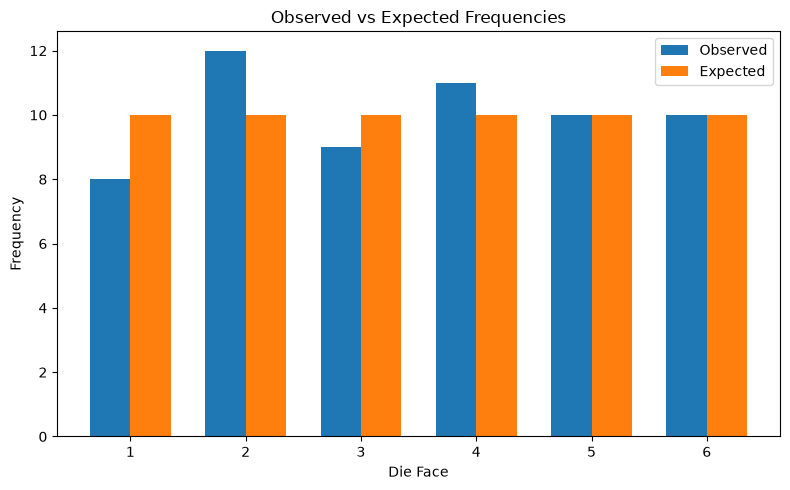

In [8]:
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    faces - width / 2,
    observed,
    width,
    label="Observed"
)

plt.bar(
    faces + width / 2,
    expected,
    width,
    label="Expected"
)

plt.xlabel("Die Face")
plt.ylabel("Frequency")
plt.title("Observed vs Expected Frequencies")
plt.xticks(faces)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Calculate the Chi-Square Statistic

The test statistic measures the discrepancy between observed and expected frequencies:


A larger statistic indicates a greater discrepancy between the observed counts and those expected under the null hypothesis.

In [9]:
contributions = (observed - expected) ** 2 / expected

contribution_table = pd.DataFrame({
    "Face": faces,
    "Observed": observed,
    "Expected": expected,
    "Chi-Square Contribution": contributions
})

display(contribution_table.round(4))

chi2_manual = contributions.sum()

print(f"Manual Chi-Square statistic: {chi2_manual:.4f}")

,Face,Observed,Expected,Chi-Square Contribution
0,1,8,10.0,0.4
1,2,12,10.0,0.4
2,3,9,10.0,0.1
3,4,11,10.0,0.1
4,5,10,10.0,0.0
5,6,10,10.0,0.0


Manual Chi-Square statistic: 1.0000


## 5. Perform the Hypothesis Test

For six categories whose probabilities are fully specified in advance, the degrees of freedom are:

\[
df=k-1=6-1=5
\]

We use the right-tailed Chi-Square test because larger values of the statistic indicate greater disagreement with the null distribution.

We calculate the test statistic and p-value using `scipy.stats.chisquare`. The p-value measures how likely it would be, assuming \(H_0\) is true, to obtain a Chi-Square statistic at least as large as the observed statistic.

In [10]:
chi2_stat, p_value = chisquare(
    f_obs=observed,
    f_exp=expected
)

df = k - 1

print(f"Chi-Square statistic: {chi2_stat:.4f}")
print(f"Degrees of freedom: {df}")
print(f"P-value: {p_value:.4f}")
print(f"Significance level: {alpha}")

if p_value < alpha:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

Chi-Square statistic: 1.0000
Degrees of freedom: 5
P-value: 0.9626
Significance level: 0.05
Decision: Fail to reject H0


## 6. Critical-Value Approach

At \(alpha=0.05\) and \(df=5\), the right-tailed critical value is approximately 11.070.

The decision rule is:

- Reject \(H_0\) if \(chi^2>11.070\).
- Otherwise, fail to reject \(H_0\).

Our test statistic is 1.00, which is below the critical value. Therefore, we fail to reject \(H_0\).

The critical-value and p-value approaches should produce the same decision.

In [11]:
critical_value = chi2.ppf(1 - alpha, df)

print(f"Critical value: {critical_value:.4f}")
print(f"Test statistic: {chi2_stat:.4f}")

if chi2_stat > critical_value:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

Critical value: 11.0705
Test statistic: 1.0000
Decision: Fail to reject H0


## 7. Measure Practical Discrepancy Using Cohen's \(w\)

Statistical significance and practical importance are different.

- **P-value:** Measures the evidence against the null hypothesis.
- **Cohen's \(w\):** Measures the standardized discrepancy between observed and expected categorical distributions.

For the Chi-Square Goodness-of-Fit Test:

$$
w = \sqrt{\sum_{i=1}^{k}\frac{(p_i-p_{0i})^2}{p_{0i}}}
$$

An equivalent formula is:

$$
w = \sqrt{\frac{\chi^2}{n}}
$$

Where:

- \(p_i\) is the observed proportion for category \(i\).
- \(p_{0i}\) is the expected proportion under the null hypothesis.
- \(\chi^2\) is the calculated Chi-Square statistic.
- \(n\) is the total number of observations.

### Calculation

For our fair-dice example:

$$
w = \sqrt{\frac{1}{60}}
$$

$$
w \approx 0.1291
$$

Cohen's commonly used guidelines are 0.1 (small), 0.3 (medium), and 0.5 (large). These are approximate guidelines, not universal thresholds.

### Interpretation

The calculated effect size is approximately 0.1291, which falls within the commonly used small-effect range. This indicates a relatively small discrepancy between the observed and expected distributions.

The effect size does not prove that the die is fair. It complements the p-value by describing the magnitude of the discrepancy.

In [12]:
cohens_w = np.sqrt(chi2_stat / n)

print(f"Cohen's w: {cohens_w:.4f}")

Cohen's w: 0.1291


## 8. Results and Interpretation

The test produces approximately:

- **Chi-Square statistic:** 1.000
- **Degrees of freedom:** 5
- **Critical value:** 11.070
- **P-value:** 0.9626
- **Cohen's \(w\):** 0.129

Since \(p>0.05\), we fail to reject the null hypothesis. The observed frequencies do not provide sufficient evidence that the die's outcomes differ from a uniform distribution.

Cohen's \(w\approx0.129\) falls within the commonly used small-effect range. This indicates a relatively small discrepancy between the observed and expected distributions in this sample.

Neither the non-significant p-value nor the effect size proves that the die is perfectly fair. The conclusion is limited to the evidence available from these 60 rolls.

## 9. Final Conclusion

The Chi-Square Goodness-of-Fit Test yielded \(chi^2=1.00\), \(df=5\), and \(p approx0.9626\). At the 5% significance level, we fail to reject the null hypothesis.

The observed frequencies are consistent with the distribution expected from a fair die. However, this does not prove fairness; it means that the sample does not provide sufficient evidence against the specified uniform distribution.

The analysis assumes independent rolls and sufficiently reliable observations.